Circle 0
Circle 0
Circle 0
Circle 0
Circle 0
Circle 1
Circle 1
Circle 1
Circle 1
Circle 1
Circle 2
Circle 2
Circle 2
Circle 2
Circle 2
Circle 3
Circle 3
Circle 3
Circle 3
Circle 3
Circle 4
Circle 4
Circle 4
Circle 4
Circle 4
Circle 5
Circle 5
Circle 5
Circle 5
Circle 5
Circle 6
Circle 6
Circle 6
Circle 6
Circle 6
Circle 7
Circle 7
Circle 7
Circle 7
Circle 7
Circle 8
Circle 8
Circle 8
Circle 8
Circle 8
Circle 9
Circle 9
Circle 9
Circle 9
Circle 9


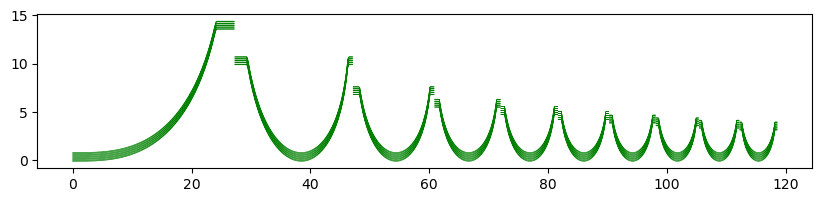

In [25]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# Параметры
M = 10        # Число радиальных слоёв
N = 4         # Число вертикальных повторений
w = 0.1       # Расстояние между кривыми
wavelength = 3.7  # Микроны
k = 2 * np.pi / wavelength  # Волновое число
f = 200       # Фокусное расстояние
Q = 100       # Детализация

# Настройка визуализации
fig, ax = plt.subplots(figsize=(10, 2))

# Предвычисление радиусов
def compute_radii(M, f, k):
    return np.sqrt(4 * f * (-np.pi / 2 + np.arange(1, M + 1) * np.pi) / k)

rt = compute_radii(M, f, k)

# Функция для интегрирования
def integrand(x):
    return np.tan((k * x ** 2) / (4 * f))

def compute_y(rt0, rt_val, Q):
    x = np.linspace(rt0, rt_val - 0.01, Q)
    y = np.array([quad(integrand, rt0, xi)[0] for xi in x])
    return x, y

def generate_and_plot_curve(x, y, n, w, ax):
    # Смещение по y
    ip = np.argmin(y)
    y_shifted = y - y[ip]
    y_original = y_shifted.copy()
    ymax = 0.5 * (np.max(x) - np.min(x))
    
    # Применение ограничений
    y_limited = np.where(y_shifted > ymax, ymax, y_shifted)
    y_lower = np.where(y_original - w > ymax, ymax, y_original - w)
    mask = y_lower <= ymax
    xt = x[mask]
    y_limited = y_limited[mask]
    y_lower = y_lower[mask]
    
    # Формирование замкнутой границы
    xx = np.concatenate([xt, xt[::-1]])
    yy = np.concatenate([y_limited, y_lower[::-1]]) + 2 * n * w
    xy = np.vstack([xx, yy]).T
    print(f"Circle {m}")
    ax.plot(xx, yy, color='green', linewidth=0.5)

# Основной цикл
for m in range(M):
    rt0 = 0 if m == 0 else rt[m - 1] + 0.1
    x, y = compute_y(rt0, rt[m], Q)
    for n in range(N + 1):
        generate_and_plot_curve(x, y, n, w, ax)

plt.show()
